In [2]:
!nvidia-smi

Sat Oct 31 19:51:46 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
%cd /content
!rm -rf ML_Hackathon_IITB
!git clone https://github.com/Shanksb/ML_Hackathon_IITB.git

PROJECT = "/content/ML_Hackathon_IITB"
%cd {PROJECT}
!ls
!ls scripts
!ls src

/content
Cloning into 'ML_Hackathon_IITB'...
remote: Enumerating objects: 64, done.
remote: Counting objects: 100% (64/64), done.
remote: Compressing objects: 100% (48/48), done.
remote: Total 64 (delta 19), reused 51 (delta 8), pack-reused 0 (from 0)
Receiving objects: 100% (64/64), 447.86 KiB | 1.87 MiB/s, done.
Resolving deltas: 100% (19/19), done.
/content/ML_Hackathon_IITB
docs  notebooks  README.md  requirements.txt  samples  scripts	src
download_weights.py  run_p1_p2.py      test_preprocess.py
patch_triposr.py     test_export.py    test_reconstruct_errors.py
run_full.py	     test_generate.py  test_reconstruct.py
export.py  __init__.py	preprocess.py  reconstruct.py  sketch_to_image.py


In [4]:
%cd {PROJECT}
!pip install -q -r requirements.txt diffusers accelerate rembg onnxruntime

/content/ML_Hackathon_IITB


In [5]:
PROJECT = "/content/ML_Hackathon_IITB"
%cd {PROJECT}
!python scripts/download_weights.py

/content/ML_Hackathon_IITB
[1/3] Cloning TripoSR ...
Cloning into '/content/ML_Hackathon_IITB/third_party/TripoSR'...
remote: Enumerating objects: 164, done.
remote: Counting objects: 100% (98/98), done.
remote: Compressing objects: 100% (53/53), done.
remote: Total 164 (delta 66), reused 45 (delta 45), pack-reused 66 (from 1)
Receiving objects: 100% (164/164), 36.71 MiB | 18.87 MiB/s, done.
Resolving deltas: 100% (68/68), done.
[2/3] Applying scikit-image patch ...
patched
[3/3] Downloading TripoSR weights (about 1.7 GB, first time only) ...
      ok: /root/.cache/huggingface/hub/models--stabilityai--TripoSR/snapshots/5b521936b01fbe1890f6f9baed0254ab6351c04a/config.yaml
      ok: /root/.cache/huggingface/hub/models--stabilityai--TripoSR/snapshots/5b521936b01fbe1890f6f9baed0254ab6351c04a/model.ckpt
Done.


In [6]:
%cd {PROJECT}
!python scripts/test_reconstruct_errors.py

/content/ML_Hackathon_IITB
[ OK ] RGB input: Input must be an RGBA image with the background removed (got mode RGB). Run prepare_for_3d() first.
[ OK ] blank RGBA: No object found in the image (background removal removed everything). Try a clearer, larger drawing.
[ OK ] tiny speck: No object found in the image (background removal removed everything). Try a clearer, larger drawing.
[ OK ] not an image: Input must be a PIL image.
[ OK ] valid chair: 41863 vertices, resolution 256, 16.85s, extents [0.57 1.07 0.6 ]


In [7]:
%cd {PROJECT}
!python scripts/test_preprocess.py
!python scripts/test_export.py
!python scripts/test_generate.py

/content/ML_Hackathon_IITB
prepare_sketch
  ok   dark strokes on white
  ok   white strokes on black
  ok   coloured strokes
  ok   tiny drawing is enlarged
  ok   transparent canvas
  ok   noisy upload
  ok   blank white canvas: The sketch looks empty. Please draw something first.
  ok   blank transparent canvas: The sketch looks empty or too faint. Please draw with a darker brush.
  ok   single tiny dot: The sketch looks empty or too faint. Please draw with a darker brush.
prepare_for_3d
  ok   object centred, fills 85% of the frame, RGBA
  ok   grey background variant (for TripoSR)
  ok   blank image / nothing to cut out: Could not find an object in the generated image. Try a clearer sketch or add a text prompt.
ALL PREPROCESS TESTS PASSED
  ok   coloured sphere exported to .glb + .obj, colours preserved: {'vertices': 642, 'faces': 1280, 'extents': [1.0, 1.0, 1.0], 'watertight': True, 'has_color_or_texture': True}
  ok   plain box without colours
  ok   Scene input is merged into on

In [8]:
%cd {PROJECT}
!mkdir -p samples/sketches

/content/ML_Hackathon_IITB


In [9]:
%cd {PROJECT}
!ls samples/sketches
!python scripts/run_full.py samples/sketches/mug.png

/content/ML_Hackathon_IITB
buds.png  chair.png  mug.png
Loading CLIP (openai/clip-vit-base-patch32) on CPU for sketch recognition...
HTTP Request: GET https://huggingface.co/api/models/openai/clip-vit-base-patch32/revision/main "HTTP/1.1 200 OK"
HTTP Request: HEAD https://huggingface.co/openai/clip-vit-base-patch32/resolve/3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268/adapter_config.json "HTTP/1.1 404 Not Found"
HTTP Request: HEAD https://huggingface.co/openai/clip-vit-base-patch32/resolve/3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268/config.json "HTTP/1.1 307 Temporary Redirect"
HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/openai/clip-vit-base-patch32/3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268/config.json?%2Fopenai%2Fclip-vit-base-patch32%2Fresolve%2F3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268%2Fconfig.json=&etag=%22a2a88b96561196777ca173b15309ea859f4d2ce0%22 "HTTP/1.1 200 OK"
HTTP Request: GET https://huggingface.co/api/resolve-cache/models/openai/clip-vit-base-patch32/3d74acf

/content/ML_Hackathon_IITB
outputs/full/mug_1_sketch.png


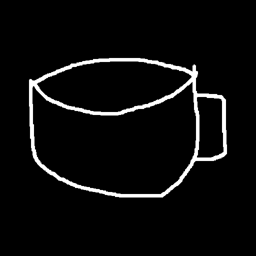

outputs/full/mug_2_generated.png


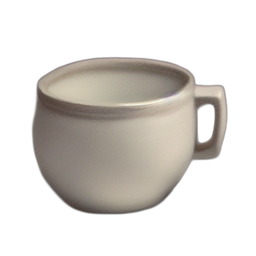

outputs/full/mug_3_for_3d.png


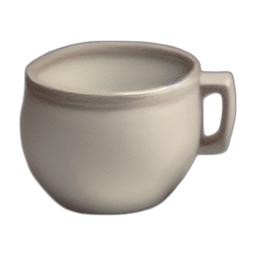

In [10]:
%cd {PROJECT}
from PIL import Image
from IPython.display import display
import glob
for f in sorted(glob.glob("outputs/full/*.png")):
    print(f)
    display(Image.open(f).resize((256, 256)))

In [1]:
%cd /content/ML_Hackathon_IITB
!git pull

/content/ML_Hackathon_IITB
remote: Enumerating objects: 7, done.
remote: Counting objects: 100% (7/7), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 4 (delta 3), reused 4 (delta 3), pack-reused 0 (from 0)
Unpacking objects: 100% (4/4), 334 bytes | 334.00 KiB/s, done.
From https://github.com/Shanksb/ML_Hackathon_IITB
   541c520..6483995  main       -> origin/main
Updating 541c520..6483995
Fast-forward
 src/reconstruct.py | 2 --
 1 file changed, 2 deletions(-)


In [11]:
   %cd {PROJECT}
   !python scripts/run_full.py samples/sketches/chair.png
   !python scripts/run_full.py samples/sketches/buds.png
   !python scripts/run_full.py samples/sketches/mug.png --seed 7

/content/ML_Hackathon_IITB
Loading CLIP (openai/clip-vit-base-patch32) on CPU for sketch recognition...
HTTP Request: GET https://huggingface.co/api/models/openai/clip-vit-base-patch32/revision/main "HTTP/1.1 200 OK"
HTTP Request: HEAD https://huggingface.co/openai/clip-vit-base-patch32/resolve/main/model.safetensors "HTTP/1.1 404 Not Found"
HTTP Request: GET https://huggingface.co/api/models/openai/clip-vit-base-patch32 "HTTP/1.1 200 OK"
HTTP Request: GET https://huggingface.co/api/models/openai/clip-vit-base-patch32/commits/main "HTTP/1.1 200 OK"
HTTP Request: GET https://huggingface.co/api/models/openai/clip-vit-base-patch32/discussions?p=0 "HTTP/1.1 200 OK"
HTTP Request: GET https://huggingface.co/api/models/openai/clip-vit-base-patch32/commits/refs%2Fpr%2F66 "HTTP/1.1 200 OK"
HTTP Request: HEAD https://huggingface.co/openai/clip-vit-base-patch32/resolve/refs%2Fpr%2F66/model.safetensors.index.json "HTTP/1.1 404 Not Found"
Loading weights: 100% 398/398 [00:00<00:00, 18912.31it/s]
HT